# WorkflowHub edges vs. citation-order edges

Compare ordered tool co-citations with tool pairs in Galaxy workflows

- **Workflows:** `data/biotools/combined/combined_edges.csv` (`map_galaxy_tools.py`): tool A feeds tool B in `n_workflows` workflows
- **Citations:** `../edges-processed/directed_edges.csv` (`citation-order/` steps 3 to 5): tool A is cited before tool B in `n_articles` articles

Each workflow pair is put in its main workflow direction, `source` → `target`. Then both sources get a direction ratio, from 0 to 1: the share of the counts that go `source` → `target`.

`distance = |wf_dir - cit_dir|` says how well the two agree: 0 = the same ratio, 1 = opposite directions (all workflows one way, all articles the other).

In [194]:
import duckdb

MAX_CONFIDENCE = 3   # workflow edges to use: 1 = Codex mapping only, 2 = + name match, 3 = all (+ prefix match)
MIN_ARTICLES = 1    # pairs with fewer articles are left out of the summary
WORKFLOW_TYPE = "nextflow"  # which workflows to count: "all", "galaxy", "nextflow" or "nfcore"

WF_DATA = "../workflows/data/biotools"
CITATIONS = "../directed-graph/edges-processed/directed_edges.csv"
WORKFLOWS = f"{WF_DATA}/combined/combined_edges.csv"

WF_COLUMNS = {"galaxy": ["n_wf_galaxy"], "nextflow": ["n_wf_nextflow"], "nfcore": ["n_wf_nfcore"]}
WF_COLUMNS["all"] = [col for cols in WF_COLUMNS.values() for col in cols]
N_WORKFLOWS = " + ".join(WF_COLUMNS[WORKFLOW_TYPE])  # KeyError here = WORKFLOW_TYPE is not one of the names above
print(f"Workflows: {WORKFLOW_TYPE} ({N_WORKFLOWS})")

con = duckdb.connect()
# Without a confidence column, confidence is empty and MAX_CONFIDENCE is not used.
HAS_CONFIDENCE = "confidence" in con.sql(f"SELECT * FROM '{WORKFLOWS}' LIMIT 0").columns
if not HAS_CONFIDENCE:
    print(f"No confidence column in {WORKFLOWS}: using all edges, no confidence filter or colours")
con.execute(f"""
    CREATE OR REPLACE TABLE wf AS
    SELECT lower(source) AS source, lower(target) AS target,
           {N_WORKFLOWS} AS n_workflows,
           {"confidence" if HAS_CONFIDENCE else "NULL::INTEGER AS confidence"}
    FROM '{WORKFLOWS}'
    WHERE {N_WORKFLOWS} > 0  -- only edges seen in the chosen workflows
          {f"AND confidence <= {MAX_CONFIDENCE}" if HAS_CONFIDENCE else ""}
""")
con.execute(f"CREATE OR REPLACE TABLE cit AS SELECT source, target, n_articles FROM '{CITATIONS}'")
con.execute("CREATE OR REPLACE TABLE cit_tools AS SELECT source AS tool FROM cit UNION SELECT target FROM cit")

# One row per workflow pair in its main direction, with the counts of both sources both ways.
con.execute(f"""
    CREATE OR REPLACE TABLE pairs AS
    WITH counts AS (
        SELECT f.source, f.target,
               f.n_workflows AS wf_fwd, coalesce(r.n_workflows, 0) AS wf_rev,
               coalesce(cf.n_articles, 0) AS cit_fwd, coalesce(cr.n_articles, 0) AS cit_rev,
               greatest(f.confidence, coalesce(r.confidence, f.confidence)) AS confidence,  -- the weaker of both directions
               f.source IN (SELECT tool FROM cit_tools) AND f.target IN (SELECT tool FROM cit_tools) AS both_in_cit
        FROM wf f
        LEFT JOIN wf r ON r.source = f.target AND r.target = f.source
        LEFT JOIN cit cf ON cf.source = f.source AND cf.target = f.target
        LEFT JOIN cit cr ON cr.source = f.target AND cr.target = f.source
        WHERE f.n_workflows > coalesce(r.n_workflows, 0)                -- the main direction,
           OR (f.n_workflows = r.n_workflows AND f.source < f.target)  -- on a tie the alphabetical one
    ),
    ratios AS (
        SELECT *,
               wf_fwd / (wf_fwd + wf_rev) AS wf_dir,
               cit_fwd / nullif(cit_fwd + cit_rev, 0) AS cit_dir
        FROM counts
    )
    SELECT *, abs(wf_dir - cit_dir) AS distance FROM ratios
""")

Workflows: nextflow (n_wf_nextflow)
No confidence column in ../workflows/data/biotools/combined/combined_edges.csv: using all edges, no confidence filter or colours


## Print edges

One row per workflow pair, ordered by number of occurances in workflows.

In [195]:
con.sql("""
    SELECT source, target, wf_fwd, wf_rev, round(wf_dir, 2) AS wf_dir,
           cit_fwd, cit_rev, round(cit_dir, 2) AS cit_dir, round(distance, 2) AS distance
    FROM pairs ORDER BY wf_fwd + wf_rev DESC, cit_fwd + cit_rev DESC
""").show(max_rows=1000)

┌──────────────────────────────────────────┬───────────────────────────────┬────────┬────────┬────────┬─────────┬─────────┬─────────┬──────────┐
│                  source                  │            target             │ wf_fwd │ wf_rev │ wf_dir │ cit_fwd │ cit_rev │ cit_dir │ distance │
│                 varchar                  │            varchar            │ int64  │ int64  │ double │  int64  │  int64  │ double  │  double  │
├──────────────────────────────────────────┼───────────────────────────────┼────────┼────────┼────────┼─────────┼─────────┼─────────┼──────────┤
│ bwa                                      │ samtools                      │     25 │     10 │   0.71 │    7096 │     283 │    0.96 │     0.25 │
│ minimap2                                 │ samtools                      │     16 │      9 │   0.64 │    1198 │     124 │    0.91 │     0.27 │
│ fastqc                                   │ multiqc                       │     22 │      2 │   0.92 │       0 │       0 │    NUL

## Statistics

Comparison of tool pairs in co-citation graph and in Galaxy workflows.


In [196]:
# Distance statistics for the pairs co-cited in at least 1, 5, 10, ... articles, optionally only a subset of pairs.
def stats(where="true"):
    con.sql(f"""
        SELECT min_articles,
               count(*)                    AS pairs_compared,
               round(avg(distance), 2)     AS mean_distance,
               round(median(distance), 2)  AS median_distance
        FROM pairs, (VALUES (1), (5), (10), (20), (50), (100), (200)) v(min_articles)
        WHERE cit_fwd + cit_rev >= min_articles AND {where}
        GROUP BY min_articles ORDER BY min_articles
    """).show()


stats()  # all pairs

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            394 │          0.35 │            0.29 │
│            5 │            284 │          0.33 │            0.27 │
│           10 │            236 │          0.31 │            0.25 │
│           20 │            187 │           0.3 │            0.24 │
│           50 │            123 │          0.29 │            0.23 │
│          100 │             94 │          0.28 │            0.23 │
│          200 │             54 │          0.28 │            0.17 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [197]:
stats("wf_fwd + wf_rev >= 2")  # pairs in at least 2 workflows

┌──────────────┬────────────────┬───────────────┬─────────────────┐
│ min_articles │ pairs_compared │ mean_distance │ median_distance │
│    int32     │     int64      │    double     │     double      │
├──────────────┼────────────────┼───────────────┼─────────────────┤
│            1 │            120 │          0.32 │            0.25 │
│            5 │            100 │          0.29 │            0.24 │
│           10 │             92 │          0.29 │            0.24 │
│           20 │             81 │          0.28 │            0.24 │
│           50 │             55 │          0.28 │            0.24 │
│          100 │             46 │          0.25 │            0.24 │
│          200 │             28 │          0.25 │            0.19 │
└──────────────┴────────────────┴───────────────┴─────────────────┘



In [198]:
if HAS_CONFIDENCE:
    stats("confidence = 1")  # pairs mapped through the Galaxy Codex only

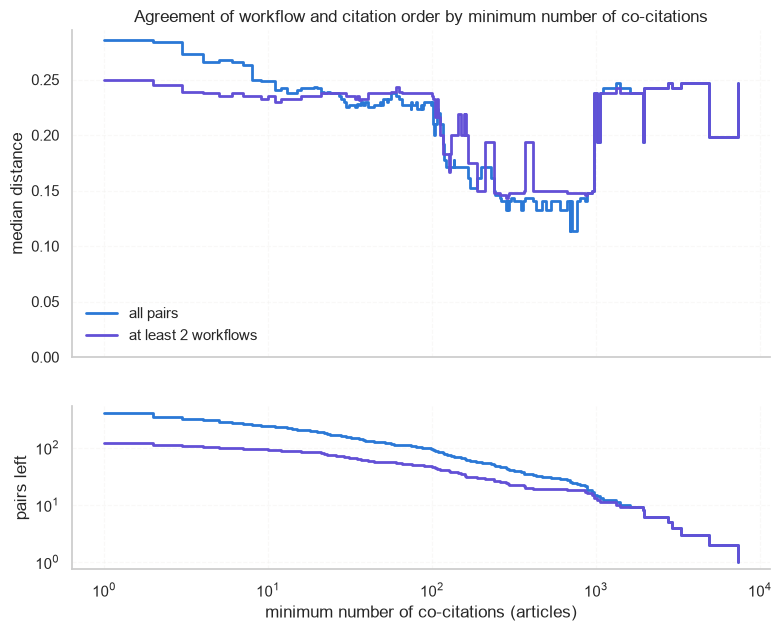

In [199]:
# Median distance for each subset at every minimum number of co-citations, and how many pairs are left.
# The confidence curve is only drawn when the edges have a confidence column.
import matplotlib.pyplot as plt

SUBSETS = [("all pairs", "true", "#2a78d6"),
           ("at least 2 workflows", "wf_fwd + wf_rev >= 2", "#6250d6")]
if HAS_CONFIDENCE:
    SUBSETS.append(("confidence 1 (Codex)", "confidence = 1", "#eda100"))

fig, (ax_median, ax_pairs) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=[2, 1])
for label, where, colour in SUBSETS:
    rows = con.execute(f"""
        WITH p AS (SELECT cit_fwd + cit_rev AS n_articles, distance FROM pairs WHERE cit_fwd + cit_rev >= 1 AND {where})
        SELECT t.n_articles AS min_articles, median(p.distance), count(*)
        FROM (SELECT DISTINCT n_articles FROM p) t JOIN p ON p.n_articles >= t.n_articles
        GROUP BY t.n_articles ORDER BY t.n_articles
    """).fetchall()
    x, median_distance, n_pairs = zip(*rows)
    ax_median.step(x, median_distance, where="post", color=colour, linewidth=2, label=label)
    ax_pairs.step(x, n_pairs, where="post", color=colour, linewidth=2)

ax_median.set(ylabel="median distance", ylim=(0, None),
              title="Agreement of workflow and citation order by minimum number of co-citations")
ax_median.legend(frameon=False)
ax_pairs.set(xscale="log", yscale="log", xlabel="minimum number of co-citations (articles)", ylabel="pairs left")
for ax in (ax_median, ax_pairs):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
plt.show()

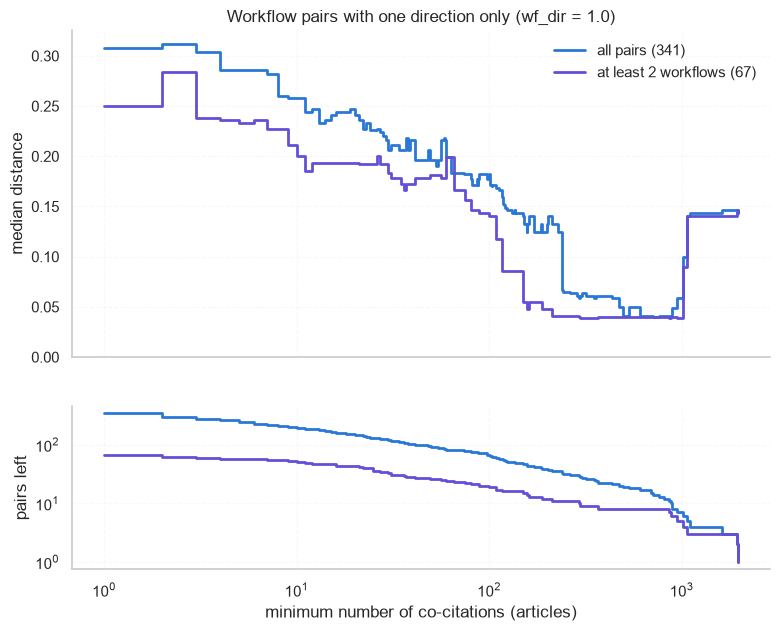

In [200]:
# The plot above for one group of workflow pairs only. This cell: pairs that go one way in every workflow (wf_dir = 1.0).
def plot_median(group, title):
    fig, (ax_median, ax_pairs) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=[2, 1])
    for label, where, colour in SUBSETS:
        rows = con.execute(f"""
            WITH p AS (SELECT cit_fwd + cit_rev AS n_articles, distance FROM pairs
                       WHERE cit_fwd + cit_rev >= 1 AND {where} AND {group})
            SELECT t.n_articles AS min_articles, median(p.distance), count(*)
            -- thresholds: every count that occurs, plus 1, so each line starts at the left edge
            FROM (SELECT DISTINCT n_articles FROM p UNION SELECT 1) t JOIN p ON p.n_articles >= t.n_articles
            GROUP BY t.n_articles ORDER BY t.n_articles
        """).fetchall()
        if not rows:  # no pairs of this subset in the group
            continue
        x, median_distance, n_pairs = zip(*rows)
        ax_median.step(x, median_distance, where="post", color=colour, linewidth=2, label=f"{label} ({n_pairs[0]})")
        ax_pairs.step(x, n_pairs, where="post", color=colour, linewidth=2)
    ax_median.set(ylabel="median distance", ylim=(0, None), title=title)
    ax_median.legend(frameon=False)
    ax_pairs.set(xscale="log", yscale="log", xlabel="minimum number of co-citations (articles)", ylabel="pairs left")
    for ax in (ax_median, ax_pairs):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(color="#ecebe7", linewidth=0.8)
        ax.set_axisbelow(True)
    plt.show()


plot_median("wf_dir = 1", "Workflow pairs with one direction only (wf_dir = 1.0)")

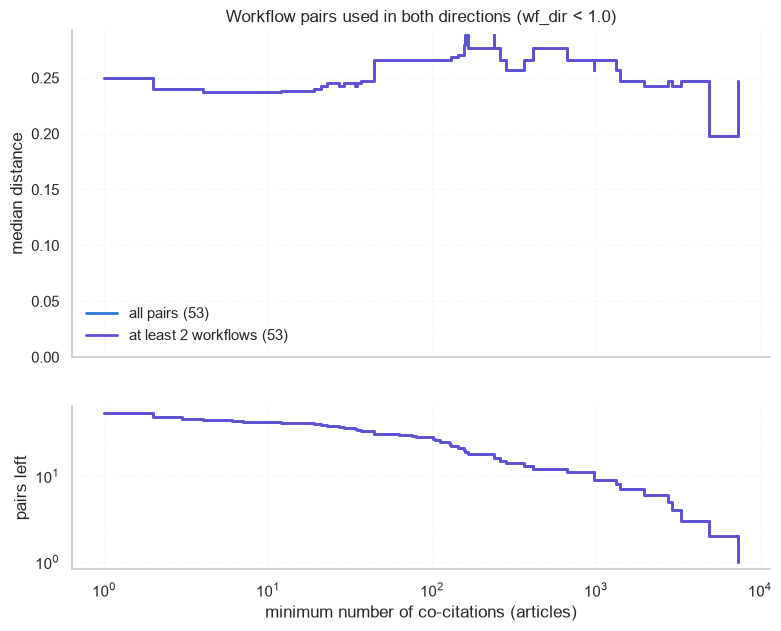

In [201]:
# The same for the rest: pairs that go both ways in workflows (wf_dir < 1.0).
plot_median("wf_dir < 1", "Workflow pairs used in both directions (wf_dir < 1.0)")

In [202]:
# The numbers behind the two plots above: for each group and subset, the pairs with at least the minimum number of
# co-citations, and their median distance. Each column includes all pairs with that many co-citations or more.
SUMMARY_MIN = [1, 5, 10, 20, 40, 100]
GROUPS = [("one direction (wf_dir = 1.0)", "wf_dir = 1"), ("both directions (wf_dir < 1.0)", "wf_dir < 1"),
          ("all workflow pairs", "true")]

print(f"{'':<34}{'':<24}" + "".join(f"{f'≥ {k}':>13}" for k in SUMMARY_MIN))
for group_label, group in GROUPS:
    for label, where, _ in SUBSETS:
        cells = con.execute(f"""
            SELECT k, count(p.distance), median(p.distance)
            FROM unnest(?::INTEGER[]) t(k)
            LEFT JOIN pairs p ON p.cit_fwd + p.cit_rev >= t.k AND {where} AND {group}
            GROUP BY k ORDER BY k
        """, [SUMMARY_MIN]).fetchall()
        print(f"{group_label:<34}{label:<24}"
              + "".join(f"{f'{n}, {m:.2f}' if n else '0':>13}" for _, n, m in cells))
    print()
print("each cell: pairs, median distance")

                                                                    ≥ 1          ≥ 5         ≥ 10         ≥ 20         ≥ 40        ≥ 100
one direction (wf_dir = 1.0)      all pairs                   341, 0.31    241, 0.29    195, 0.26    148, 0.24     99, 0.20     67, 0.18
one direction (wf_dir = 1.0)      at least 2 workflows         67, 0.25     57, 0.23     51, 0.20     42, 0.19     27, 0.18     19, 0.14

both directions (wf_dir < 1.0)    all pairs                    53, 0.25     43, 0.24     41, 0.24     39, 0.24     31, 0.27     27, 0.27
both directions (wf_dir < 1.0)    at least 2 workflows         53, 0.25     43, 0.24     41, 0.24     39, 0.24     31, 0.27     27, 0.27

all workflow pairs                all pairs                   394, 0.29    284, 0.27    236, 0.25    187, 0.24    130, 0.23     94, 0.23
all workflow pairs                at least 2 workflows        120, 0.25    100, 0.24     92, 0.24     81, 0.24     58, 0.24     46, 0.24

each cell: pairs, median distance


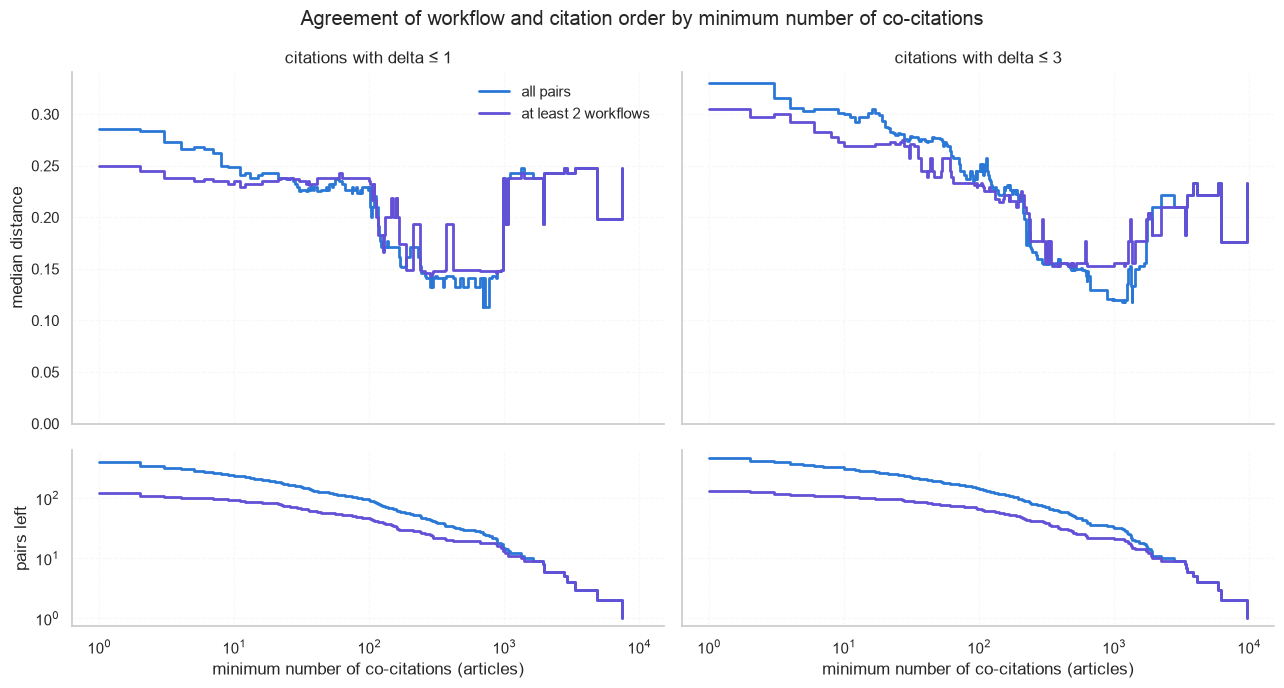

In [203]:
# The plot above, side by side for citation edges made with different maximum delta (citation-order step 5, --max-delta).
# Each file gets its own pairs table in pairs_by_file. The pairs table above is not changed.
import matplotlib.pyplot as plt

CIT_FILES = {"delta ≤ 1": "../directed-graph/edges-processed/directed_edges.csv",
             "delta ≤ 3": "../directed-graph/edges-processed/directed_edges_delta3.csv"}
             # "all citations": "../directed-graph/edges-processed/directed_edges_old.csv"

con.execute("CREATE OR REPLACE TABLE pairs_by_file (file VARCHAR, wf_fwd BIGINT, wf_rev BIGINT, confidence INTEGER, n_articles BIGINT, distance DOUBLE)")
for name, path in CIT_FILES.items():
    # Same pairing as the setup cell: each workflow pair in its main direction, with its citations both ways.
    con.execute(f"""
        INSERT INTO pairs_by_file
        WITH cit_file AS (SELECT source, target, n_articles FROM '{path}'),
        counts AS (
            SELECT f.n_workflows AS wf_fwd, coalesce(r.n_workflows, 0) AS wf_rev,
                   greatest(f.confidence, coalesce(r.confidence, f.confidence)) AS confidence,
                   coalesce(cf.n_articles, 0) AS cit_fwd, coalesce(cr.n_articles, 0) AS cit_rev
            FROM wf f
            LEFT JOIN wf r ON r.source = f.target AND r.target = f.source
            LEFT JOIN cit_file cf ON cf.source = f.source AND cf.target = f.target
            LEFT JOIN cit_file cr ON cr.source = f.target AND cr.target = f.source
            WHERE f.n_workflows > coalesce(r.n_workflows, 0)
               OR (f.n_workflows = r.n_workflows AND f.source < f.target)
        )
        SELECT ?, wf_fwd, wf_rev, confidence, cit_fwd + cit_rev,
               abs(wf_fwd / (wf_fwd + wf_rev) - cit_fwd / nullif(cit_fwd + cit_rev, 0))
        FROM counts
    """, [name])

fig, axes = plt.subplots(2, len(CIT_FILES), figsize=(6.5 * len(CIT_FILES), 7), sharex=True, sharey="row",
                         height_ratios=[2, 1], squeeze=False)
for col, name in enumerate(CIT_FILES):
    ax_median, ax_pairs = axes[:, col]
    for label, where, colour in SUBSETS:
        rows = con.execute(f"""
            WITH p AS (SELECT n_articles, distance FROM pairs_by_file WHERE file = ? AND n_articles >= 1 AND {where})
            SELECT t.n_articles AS min_articles, median(p.distance), count(*)
            FROM (SELECT DISTINCT n_articles FROM p) t JOIN p ON p.n_articles >= t.n_articles
            GROUP BY t.n_articles ORDER BY t.n_articles
        """, [name]).fetchall()
        x, median_distance, n_pairs = zip(*rows)
        ax_median.step(x, median_distance, where="post", color=colour, linewidth=2, label=label)
        ax_pairs.step(x, n_pairs, where="post", color=colour, linewidth=2)
    ax_median.set_title(f"citations with {name}")
    ax_pairs.set(xscale="log", yscale="log", xlabel="minimum number of co-citations (articles)")
axes[0, 0].set(ylabel="median distance", ylim=(0, None))  # after all panels, so the shared top fits every curve
axes[1, 0].set_ylabel("pairs left")
axes[0, 0].legend(frameon=False)
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle("Agreement of workflow and citation order by minimum number of co-citations")
plt.tight_layout()
plt.show()


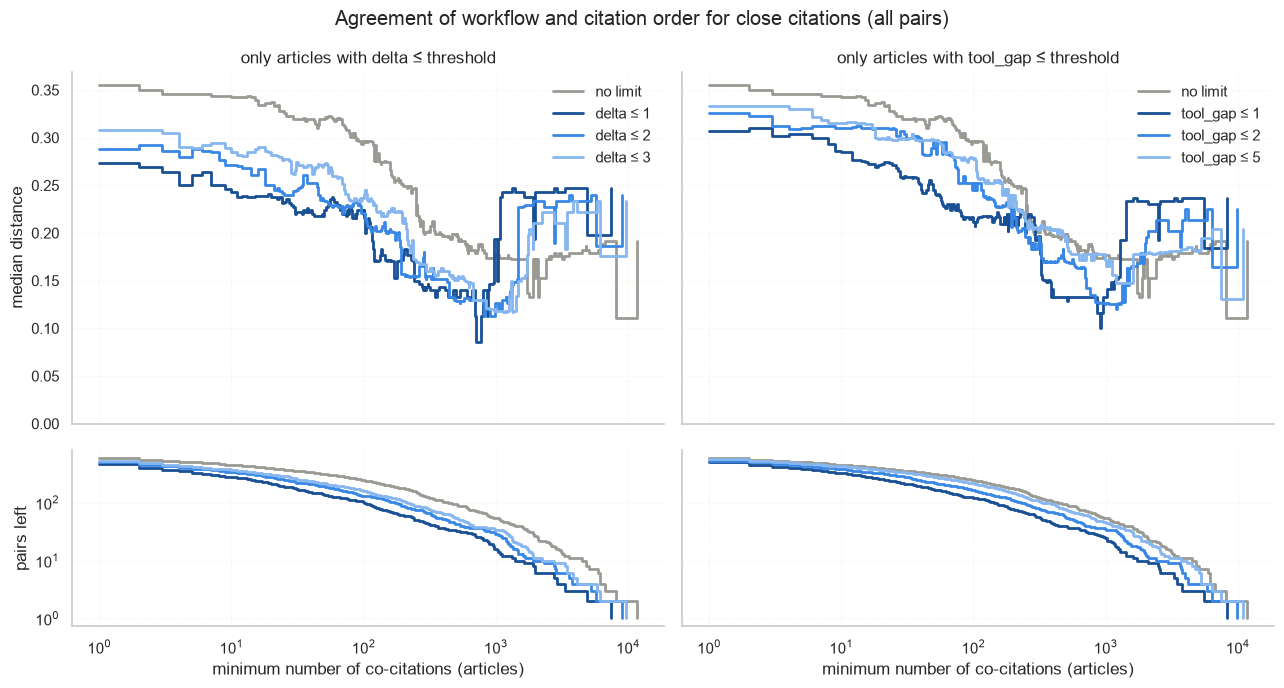

In [204]:
# The same curves, but the citation direction only counts articles where the two tools are cited close together.
# delta: references between the two citations (any reference), tool_gap: tools between them.
# Needs the per-article pairs (citation-order step 4) from the same run as the citation edges above.
import matplotlib.pyplot as plt

RAW = "../directed-graph/edges-processed/directed_edges_raw-all_citations.parquet"
GAP_THRESHOLDS = {"delta": [1, 2, 3, 10], "tool_gap": [1, 2, 5]}  # maximum distance in the article, None = no limit
GAP_SUBSET = "true"  # which workflow pairs, e.g. "wf_fwd + wf_rev >= 2" or "confidence = 1"
GAP_COLOURS = ["#9a9a94", "#184f95", "#3987e5", "#86b6ef"]  # no limit grey, then stricter is darker

# One row per article and workflow pair, fwd = cited in the workflow direction.
con.execute(f"""
    CREATE OR REPLACE TABLE cit_raw AS
    WITH r AS (SELECT lower(source) AS source, lower(target) AS target, delta, tool_gap FROM '{RAW}')
    SELECT p.source, p.target, true AS fwd, r.delta, r.tool_gap
    FROM pairs p JOIN r ON r.source = p.source AND r.target = p.target
    UNION ALL
    SELECT p.source, p.target, false, r.delta, r.tool_gap
    FROM pairs p JOIN r ON r.source = p.target AND r.target = p.source
""")


def gap_curve(column, max_gap):
    """Median distance and pairs left at every minimum number of co-citations, counting only articles within max_gap."""
    return con.execute(f"""
        WITH counts AS (
            SELECT source, target, count(*) FILTER (fwd) AS cit_fwd, count(*) FILTER (NOT fwd) AS cit_rev
            FROM cit_raw WHERE {"true" if max_gap is None else f"{column} <= {max_gap}"}
            GROUP BY source, target
        ),
        p AS (
            SELECT c.cit_fwd + c.cit_rev AS n_articles, abs(pairs.wf_dir - c.cit_fwd / (c.cit_fwd + c.cit_rev)) AS distance
            FROM counts c JOIN pairs USING (source, target)
            WHERE {GAP_SUBSET}
        )
        SELECT t.n_articles AS min_articles, median(p.distance), count(*)
        FROM (SELECT DISTINCT n_articles FROM p) t JOIN p ON p.n_articles >= t.n_articles
        GROUP BY t.n_articles ORDER BY t.n_articles
    """).fetchall()


fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey="row", height_ratios=[2, 1])
for col, (column, thresholds) in enumerate(GAP_THRESHOLDS.items()):
    ax_median, ax_pairs = axes[:, col]
    for max_gap, colour in zip([None] + thresholds, GAP_COLOURS):
        x, median_distance, n_pairs = zip(*gap_curve(column, max_gap))
        label = "no limit" if max_gap is None else f"{column} ≤ {max_gap}"
        ax_median.step(x, median_distance, where="post", color=colour, linewidth=2, label=label)
        ax_pairs.step(x, n_pairs, where="post", color=colour, linewidth=2)
    ax_median.set(ylim=(0, None), title=f"only articles with {column} ≤ threshold")
    ax_median.legend(frameon=False)
    ax_pairs.set(xscale="log", yscale="log", xlabel="minimum number of co-citations (articles)")
axes[0, 0].set_ylabel("median distance")
axes[1, 0].set_ylabel("pairs left")
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#ecebe7", linewidth=0.8)
    ax.set_axisbelow(True)
fig.suptitle(f"Agreement of workflow and citation order for close citations ({GAP_SUBSET if GAP_SUBSET != 'true' else 'all pairs'})")
plt.tight_layout()
plt.show()


In [205]:
# Count of pairs with at least 2 workflows
con.execute("SELECT count(*) FROM pairs WHERE wf_fwd + wf_rev >= 2",
                       ).fetchall()


[(232,)]

In [206]:
# Plot of workflow direction vs. citation direction, one dot per pair, one panel per minimum number of articles.
# On the diagonal both sources have the same ratio.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BLUE = "#2a78d6"
COLOURS = {1: ("#2a78d6", "1: Codex"), 2: ("#eb6834", "2: name match"), 3: ("#1baf7a", "3: prefix match")}
SIZES = [("1 workflow", 1, 2, 12), ("2-4 workflows", 2, 5, 25), ("5+ workflows", 5, 10**9, 50)]


def dot_size(n_workflows):
    return next(size for _, low, high, size in SIZES if low <= n_workflows < high)


def legend(ax, items, title=None):
    """A legend of round markers: items are (label, colour, area)."""
    handles = [Line2D([], [], marker="o", linestyle="", color=colour, markersize=area ** 0.5) for _, colour, area in items]
    ax.add_artist(ax.legend(handles, [label for label, _, _ in items], title=title, loc="lower left", frameon=False))


def plot_pairs(min_articles_list=(1, 20, 100), colour_by_confidence=False, size_by_workflows=False):
    colour_by_confidence = colour_by_confidence and HAS_CONFIDENCE  # no colours without a confidence column
    fig, axes = plt.subplots(1, len(min_articles_list), figsize=(5 * len(min_articles_list), 5.5), sharey=True)
    for ax, min_articles in zip(axes, min_articles_list):
        rows = con.execute("""
            SELECT wf_dir, cit_dir, wf_fwd + wf_rev, confidence FROM pairs
            WHERE cit_fwd + cit_rev >= ? ORDER BY confidence DESC  -- confidence 1 drawn last, on top
        """, [min_articles]).fetchall()
        x, y, n_workflows, confidence = zip(*rows)
        ax.plot([0, 1], [0, 1], color="#b0afa8", linewidth=1, zorder=1)
        ax.scatter(x, y,
                   s=[dot_size(n) for n in n_workflows] if size_by_workflows else 20,
                   c=[COLOURS[c][0] for c in confidence] if colour_by_confidence else BLUE,
                   alpha=0.6, edgecolor="white", linewidth=0.5, zorder=2)
        ax.set(xlim=(0, 1.02), ylim=(-0.02, 1.02), aspect="equal",
               xlabel="order of tool pairs in workflows",
               title=f"at least {min_articles} co-citations: {len(rows)} tool pairs")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(color="#ecebe7", linewidth=0.8)
        ax.set_axisbelow(True)
    axes[0].set_ylabel("order of tool pairs in co-citations")
    if size_by_workflows:
        legend(axes[0], [(label, "#9a9a94", size) for label, _, _, size in SIZES])
    if colour_by_confidence:
        legend(axes[1 if size_by_workflows else 0], [(label, colour, 36) for colour, label in COLOURS.values()],
               title="confidence")
    plt.show()

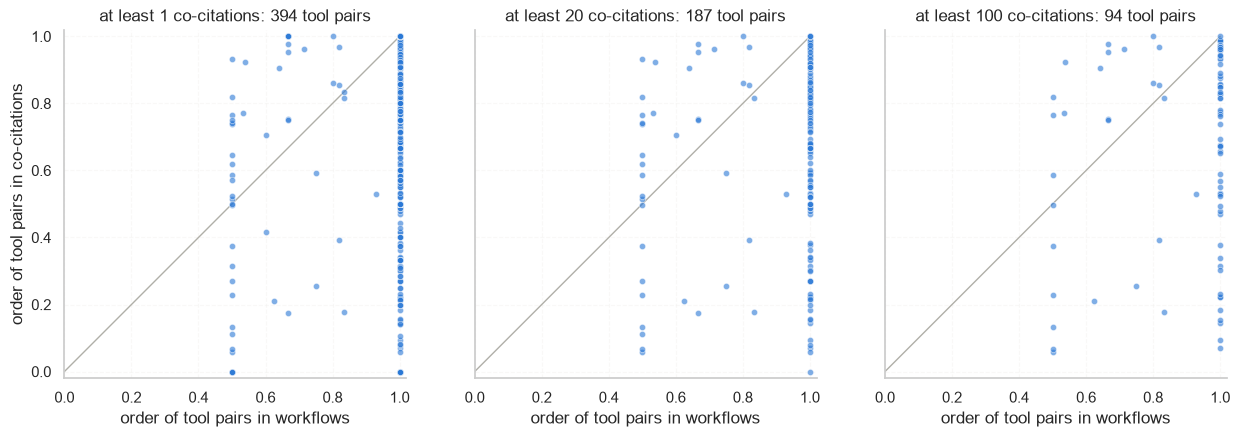

In [207]:
# All dots the same size and colour.
plot_pairs()

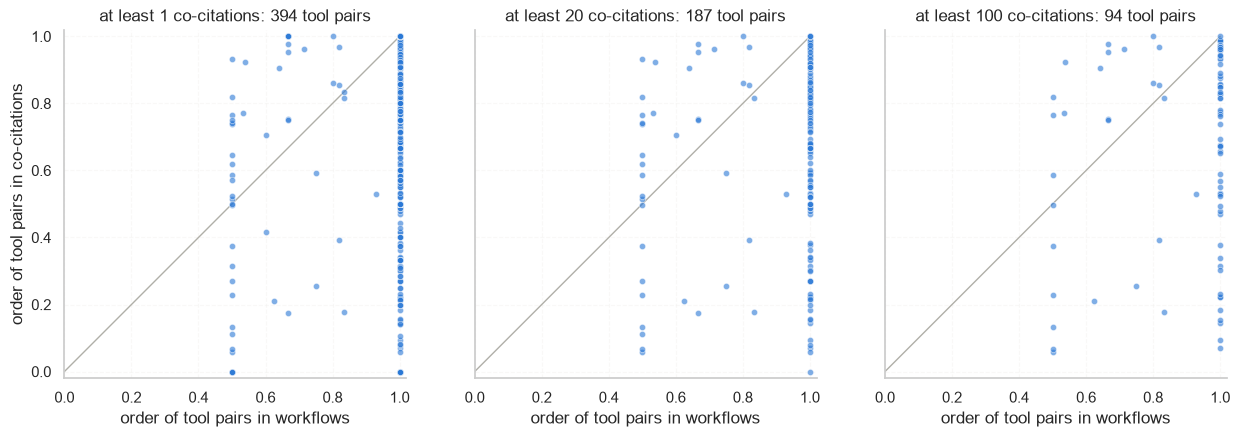

In [208]:
# Colour: mapping confidence of the pair.
plot_pairs(colour_by_confidence=True)

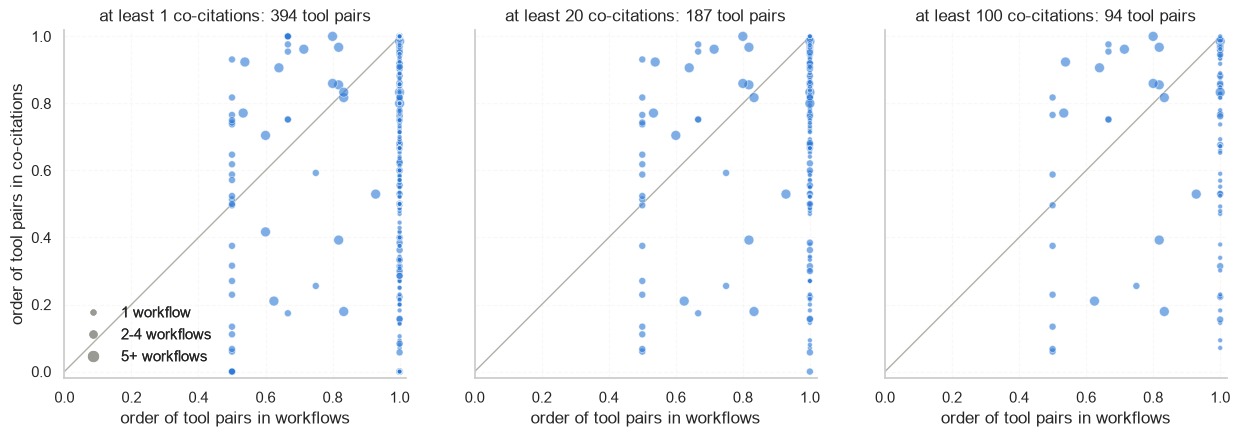

In [209]:
# Colour: mapping confidence. Dot size: number of workflows with the pair (1, 2 to 4, 5 or more).
plot_pairs(colour_by_confidence=True, size_by_workflows=True)

## Used edges statistics

How many workflow pairs could be in the citation graph (both tools are in it somewhere), and how many are.

In [210]:
con.sql("""
    UNPIVOT (
        SELECT count(*)                                         AS "workflow pairs",
               count(*) FILTER (both_in_cit)                    AS "both tools in the citation graph",
               count(*) FILTER (cit_dir IS NOT NULL)            AS "also a citation edge",
               count(*) FILTER (cit_fwd + cit_rev >= 5)         AS "citation edge, at least 5 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 10)        AS "citation edge, at least 10 articles",
               count(*) FILTER (cit_fwd + cit_rev >= 20)        AS "citation edge, at least 20 articles"
        FROM pairs
    ) ON COLUMNS(*) INTO NAME measure VALUE pairs
""").show()

┌─────────────────────────────────────┬───────┐
│               measure               │ pairs │
│               varchar               │ int64 │
├─────────────────────────────────────┼───────┤
│ workflow pairs                      │  1109 │
│ both tools in the citation graph    │   604 │
│ also a citation edge                │   394 │
│ citation edge, at least 5 articles  │   284 │
│ citation edge, at least 10 articles │   236 │
│ citation edge, at least 20 articles │   187 │
└─────────────────────────────────────┴───────┘



# More plots

In [211]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [212]:

sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3, "grid.linestyle": "--"})
COLOUR = "#f2634c"

In [213]:
direction_df = con.execute("""
    SELECT wf_dir, cit_dir,
           wf_fwd + wf_rev   AS wf_total,
           cit_fwd + cit_rev AS cit_total,
           confidence
    FROM pairs
    WHERE cit_fwd + cit_rev >= ? ORDER BY confidence DESC
""", [1]).df()

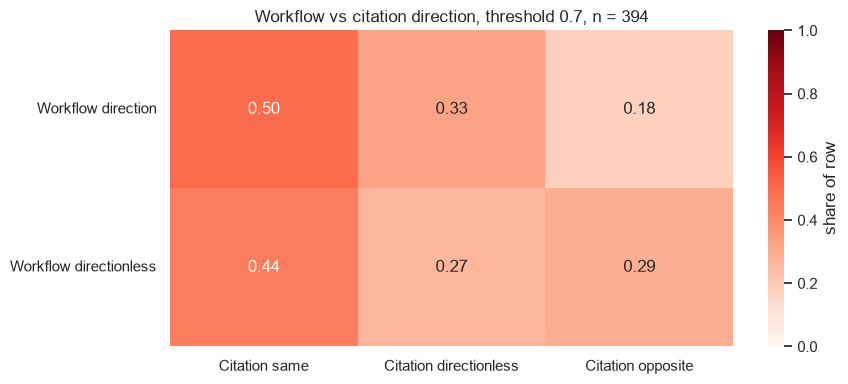

class_cit      same  directionless  opposite
class_wf                                    
direction       175            115        63
directionless    18             11        12
agreement when workflow has a direction: 0.5 (n = 353)
agreement when both have a clear direction: 0.74 (n = 238)


In [214]:
"""
Wf Direction
Wf Directionless
                cit same cit opposite cit directionless

"""
THRESHOLD = 0.70  # direction threshold; 1 - t is the opposite threshold

ROWS = ["direction", "directionless"]
COLS = ["same", "directionless", "opposite"]

# wf_dir is always >= 0.5 (main workflow direction), so only two row classes
direction_df["class_wf"] = np.where(direction_df["wf_dir"] > THRESHOLD, "direction", "directionless")
direction_df["class_cit"] = np.select(
    [direction_df["cit_dir"] > THRESHOLD, direction_df["cit_dir"] < 1 - THRESHOLD],
    ["same", "opposite"],
    default="directionless",
)

counts = (pd.crosstab(direction_df["class_wf"], direction_df["class_cit"])
            .reindex(index=ROWS, columns=COLS, fill_value=0))
norm = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(norm, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "share of row"})
ax.set_xticklabels([f"Citation {c}" for c in COLS])
ax.set_yticklabels([f"Workflow {r}" for r in ROWS], rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title(f"Workflow vs citation direction, threshold {THRESHOLD}, n = {len(direction_df)}")
plt.tight_layout()
plt.show()

print(counts)
d = counts.loc["direction"]
print("agreement when workflow has a direction:",
      round(d["same"] / d.sum(), 2) if d.sum() else "n/a", f"(n = {d.sum()})")
print("agreement when both have a clear direction:",
      round(d["same"] / (d["same"] + d["opposite"]), 2) if d["same"] + d["opposite"] else "n/a",
      f"(n = {d['same'] + d['opposite']})")

19 284


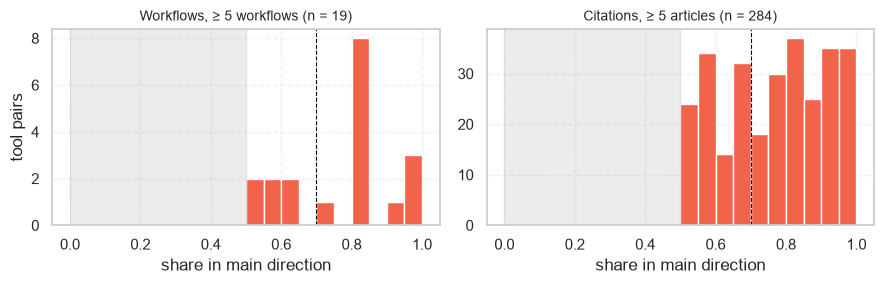

In [215]:
MIN_CIT = 5   # articles
MIN_WF = 5    # workflows
BINS = np.linspace(0, 1, 21)  # 0.05 bins

s_wf = direction_df.loc[direction_df["wf_total"] >= MIN_WF, "wf_dir"]
s_cit = direction_df.loc[direction_df["cit_total"] >= MIN_CIT, "cit_dir"]
s_cit = np.maximum(s_cit, 1 - s_cit)  # update so its also on one side of 0.5: 0.2 -> 0.8

print(len(s_wf), len(s_cit))

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharex=True)
axes[0].hist(s_wf, bins=BINS, color=COLOUR)
axes[0].set_title(f"Workflows, ≥ {MIN_WF} workflows (n = {len(s_wf)})", fontsize=10)
axes[1].hist(s_cit, bins=BINS, color=COLOUR)
axes[1].set_title(f"Citations, ≥ {MIN_CIT} articles (n = {len(s_cit)})", fontsize=10)

for ax in axes:
    ax.axvspan(0, 0.5, color="grey", alpha=0.15)  # not possible: main direction by definition
    ax.axvline(THRESHOLD, color="black", ls="--", lw=0.8)
    ax.set_xlabel("share in main direction")
axes[0].set_ylabel("tool pairs")
plt.tight_layout()
plt.show()

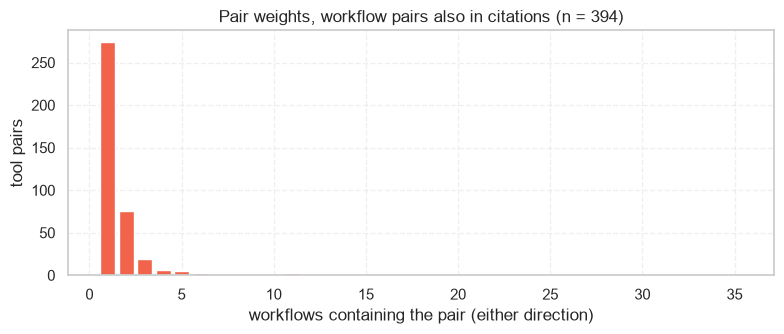

In [216]:
counts_wf = direction_df["wf_total"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts_wf.index, counts_wf.values, width=0.8, color=COLOUR)
ax.set_xlabel("workflows containing the pair (either direction)")
ax.set_ylabel("tool pairs")
ax.set_title(f"Pair weights, workflow pairs also in citations (n = {len(direction_df)})")
plt.tight_layout()
plt.show()

## Citation pairs by delta and co-citations

Tool pairs in the whole citation graph (`directed_edges_raw-all_citations.parquet`), not only the workflow pairs.

In [217]:
# Tool pairs left for each maximum delta (rows) and minimum number of co-citations (columns).
# Co-citations only count the articles within the maximum delta. None = no limit.
RAW_ALL = "../directed-graph/edges-processed/directed_edges_raw-all_citations.parquet"
DELTAS = [1, 2, 3, 5, 10, None]
MIN_COCITATIONS = [1, 5, 10, 20, 30, 40, 100]

delta_name = {d: "all" if d is None else f"≤ {d}" for d in DELTAS}
# One row per tool pair, with its co-citations within each maximum delta.
con.execute(f"""
    CREATE OR REPLACE TABLE cit_pairs_by_delta AS
    SELECT least(source, target) AS a, greatest(source, target) AS b,
           {", ".join(f'count(*) FILTER ({"true" if d is None else f"delta <= {d}"}) AS "{delta_name[d]}"' for d in DELTAS)}
    FROM '{RAW_ALL}' GROUP BY a, b
""")
rows = con.execute(" UNION ALL ".join(
    f"""SELECT '{delta_name[d]}' AS delta, {", ".join(f'count(*) FILTER ("{delta_name[d]}" >= {k})' for k in MIN_COCITATIONS)}
        FROM cit_pairs_by_delta"""
    for d in DELTAS)).fetchall()


def short(n):
    """2851234 -> 2.85M, 759669 -> 760K, 7434 -> 7.43K."""
    for size, unit in ((1e6, "M"), (1e3, "K")):
        if n >= size:
            return f"{n / size:.3g}{unit}"
    return str(n)


print("delta" + "".join(f"{f'≥ {k}':>9}" for k in MIN_COCITATIONS))
for delta, *counts in rows:
    print(f"{delta:<5}" + "".join(f"{short(n):>9}" for n in counts))

delta      ≥ 1      ≥ 5     ≥ 10     ≥ 20     ≥ 30     ≥ 40    ≥ 100
≤ 1       760K     135K    74.9K    35.1K    24.2K    20.4K    7.43K
≤ 2       1.1M     228K     127K    68.5K    46.3K    35.8K    13.6K
≤ 3      1.37M     291K     167K    93.9K    65.9K    50.1K    17.3K
≤ 5      1.74M     398K     228K     134K    90.4K    72.5K    29.7K
≤ 10     2.27M     595K     313K     184K     133K     104K    43.7K
all      2.85M     785K     422K     248K     177K     141K      61K
